# Basic usage on lifecycle benchmarks

In this example, we show how to use the `atmosphere_bgs` package to compute a Modified Lagrangian Mean (MLM) state of the atmosphere using optimal transport. The 3-dimensional state of the atmosphere for which we compute an MLM state is the initial state of the Life Cycle 1 baroclinic wave, as defined by Thorncroft, Hoskins & McIntyre (1993) and simulated in Methven, Hoskins & Bishop (2005).

For simplicity, in this example we take this input data as given. This includes 3-d mass and circulation integrals computed within contours of potential vorticity on isentropic levels.  (The package `enm`, which is also listed on the `s2senm` GitHub organisation page, can be used to generate this input data from 3-d atmospheric data for a number of atmospheric models and reanalyses, including ERA5.)

We begin by installing `atmosphere_bgs` in the active environment.

In [1]:
%pip install atmosphere_bgs

Note: you may need to restart the kernel to use updated packages.


Next we import the `atmosphere_bgs` package and prepare the input data for use in the optimal transport computation. `path` is the location of the netCDF file containing the saved input data. It is important to set the minimum pressure `pmin` and the reference pressure `p00` to appropriate values.

The main functionality of this step is to use the input 3-dimensional mass and circulation integrals to generate a target measure $\nu$ representing a normalised mass distribution in coorindates $(z,\theta)$, where $z$ is zonal angular momentum and $\theta$ is potential temperature. The mass distribution is interpolated on each isentropic level onto a regular grid in $z$. Appropriate limits in sine-of-latitude, $s_{\min}$ and $s_{\max}$, are set automatically using the processed input data. The masses are normalised to total to $(s_{\max}-s_{\min})\times (p_{00}-p_{\min})$ so have units Pascals.

In [2]:
import atmosphere_bgs

path = '../../input_data/mass_circ_lc1_2001010000.nc'
input_data = atmosphere_bgs.DataLoader(path,pmin=10,p00=1e+5)

/home/users/cq934523/.conda/envs/enm-env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


We can visualise the target measure $\nu$ using a simple scatter plot with points coloured by normalised mass.

Here we subsample points for visibiilty. The resulting pattern is a consequence of the particular ennuration of points. The mass at the top isentropic level is synthetic and is added to account for missing upper isentropic levels.

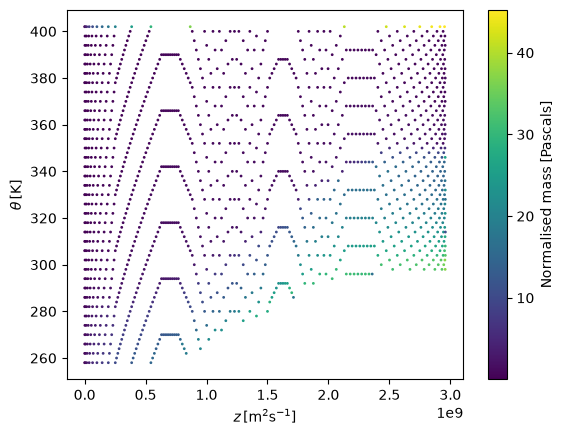

In [3]:
import matplotlib.pyplot as plt

ss = 12
z = input_data.y[::ss,0]
th = input_data.y[::ss,1]
m = input_data.tmn[::ss]

fig, ax = plt.subplots(1,1)
im = ax.scatter(z,th,s=1,c=m)
ax.set_aspect('auto')
ax.set_xlabel('$z\\, [\\mathrm{m}^2\\mathrm{s}^{-1}]$')
ax.set_ylabel('$\\theta\\, [\\mathrm{K}]$')
cb = plt.colorbar(im,ax=ax,label='Normalised mass [Pascals]')

Now we compute the MLM state by solving a semi-discrete optimal transport problem. 

The target measure is $\nu$ and the source measure is uniform in coordinates sine-of-latitude $s$ and pressure $p$ on the domain $X=[s_{\min},s_{\max}]\times[p_{\min},p_{\max}]$. The default value of $p_{\max}$ is `1e+11`, which is well above the maximum pressure in the atmosphere. The semi-discrete optimal transport solver effectively partitions the domain $X$ into regions, called _Laguerre cells_, which are each associated to a single mass point of the target measure $\nu$ and take the corresponding value of $z$ and $\theta$. One of these cells represents below ground, and surface pressure is obtained as its boundary. The solver ensures that the mass of each Laguerre cell is equal to the mass at the corresponding point of the target measure, up to a relative tolerance `ot_tol` that may be passed as an optional argument. (Since the target masses typically vary across upto 9 orders of magnitude, the solution is very accurate even with `ot_tol=1e-4`, and it is not recommeded to make `ot_tol` much smaller than this.)

In [4]:
solv = atmosphere_bgs.OTSolver(input_data,ot_tol=1e-4)  # solver class with input data and solver bound method get_bgs
ld, duals = solv.get_bgs(verbose=True)                  # call the bound method get_bgs with verbose set to True to see progress of the solver

initial duals calculated
try to fix 0 bad areas
it=-1, lr=1.00e-05, good_areas=16065/16065
it=0, lr=2.00e-05, good_areas=16065/16065, meanerr=1.105064e+00, l2err = 4.213737e+02, max_err=2.237802e+02
it=1, lr=4.00e-05, good_areas=16065/16065, meanerr=1.105020e+00, l2err = 4.213569e+02, max_err=2.237712e+02
it=2, lr=8.00e-05, good_areas=16065/16065, meanerr=1.104933e+00, l2err = 4.213234e+02, max_err=2.237533e+02
it=3, lr=1.60e-04, good_areas=16065/16065, meanerr=1.104757e+00, l2err = 4.212562e+02, max_err=2.237175e+02
it=4, lr=3.20e-04, good_areas=16065/16065, meanerr=1.104406e+00, l2err = 4.211220e+02, max_err=2.236460e+02
it=5, lr=6.40e-04, good_areas=16065/16065, meanerr=1.103704e+00, l2err = 4.208537e+02, max_err=2.235029e+02
it=6, lr=1.28e-03, good_areas=16065/16065, meanerr=1.102300e+00, l2err = 4.203173e+02, max_err=2.232169e+02
it=7, lr=2.56e-03, good_areas=16065/16065, meanerr=1.099495e+00, l2err = 4.192461e+02, max_err=2.226457e+02
it=8, lr=5.12e-03, good_areas=16065/16065, me

The semi-discrete optmial transport solver works by maximising a concave function, sometimes called the Kantorovich dual functional, for a dual vector $\psi$, called the Kantorovich potential. The Kantorovich potential has as many components as there are mass points in $\nu$. Together, the Kantorovich potential and the points $(z,\theta)$ at which $\nu$ has mass generate the _optimal Laguerre tessellation_.

We plot the optimal Laguerre tessellation with the cells coloured by zonal angular momentum, potential temperature and, for illustration, zonal wind $u$. Here, we compute the zonal wind on each cell using the value of $z$ on that cell and the $s$-coordinate of the cell centroid via the equation

$$u = \frac{z}{a\sqrt{1-s^2}} - 2\Omega a \sqrt{1-s^2}.$$

fixed 0 intersects
fixed 0 intersects
fixed 0 intersects


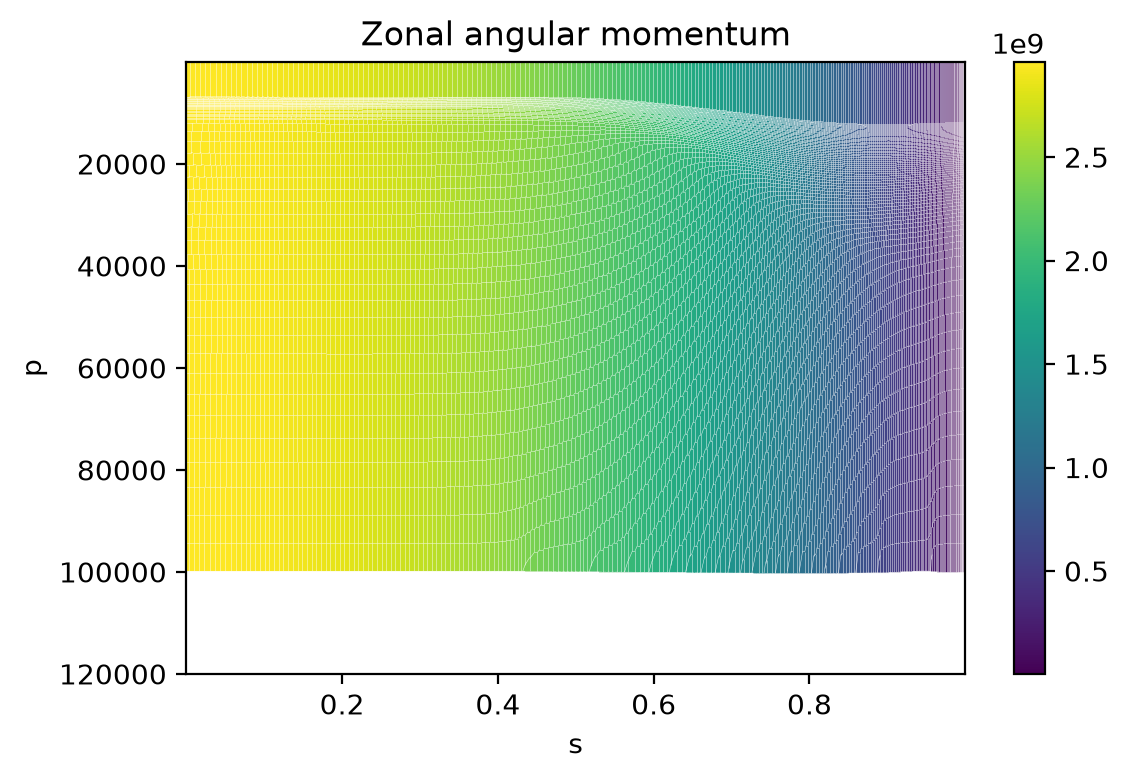

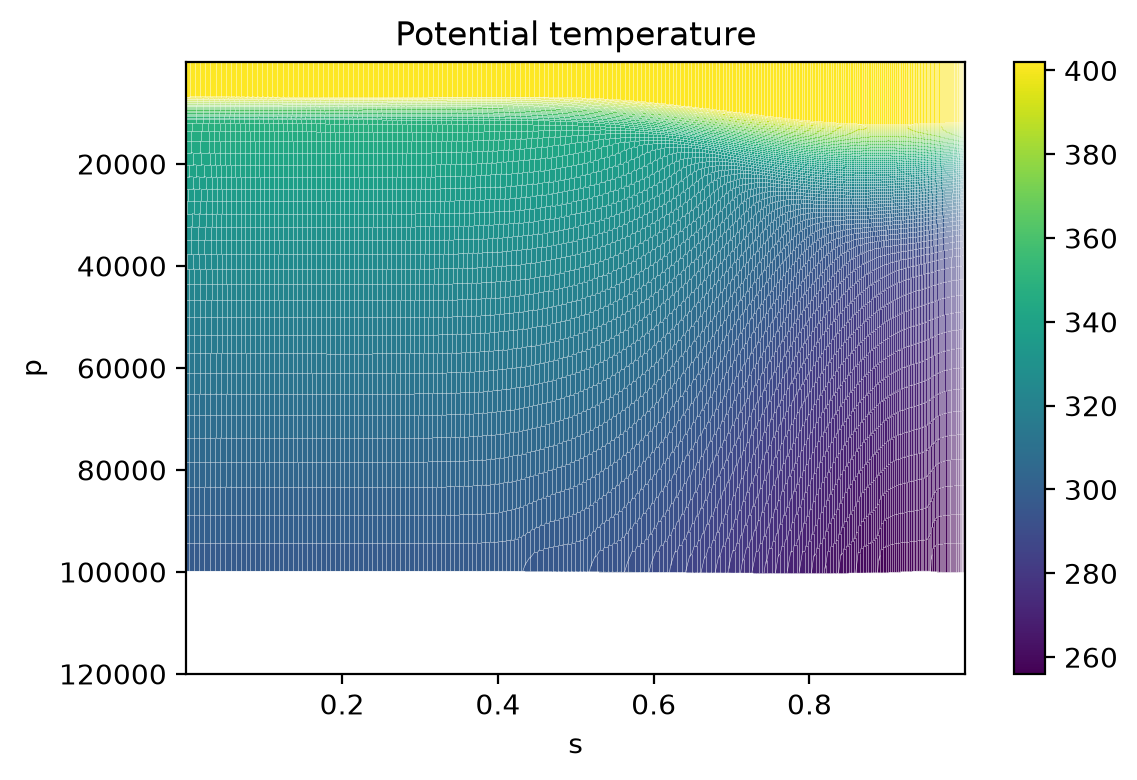

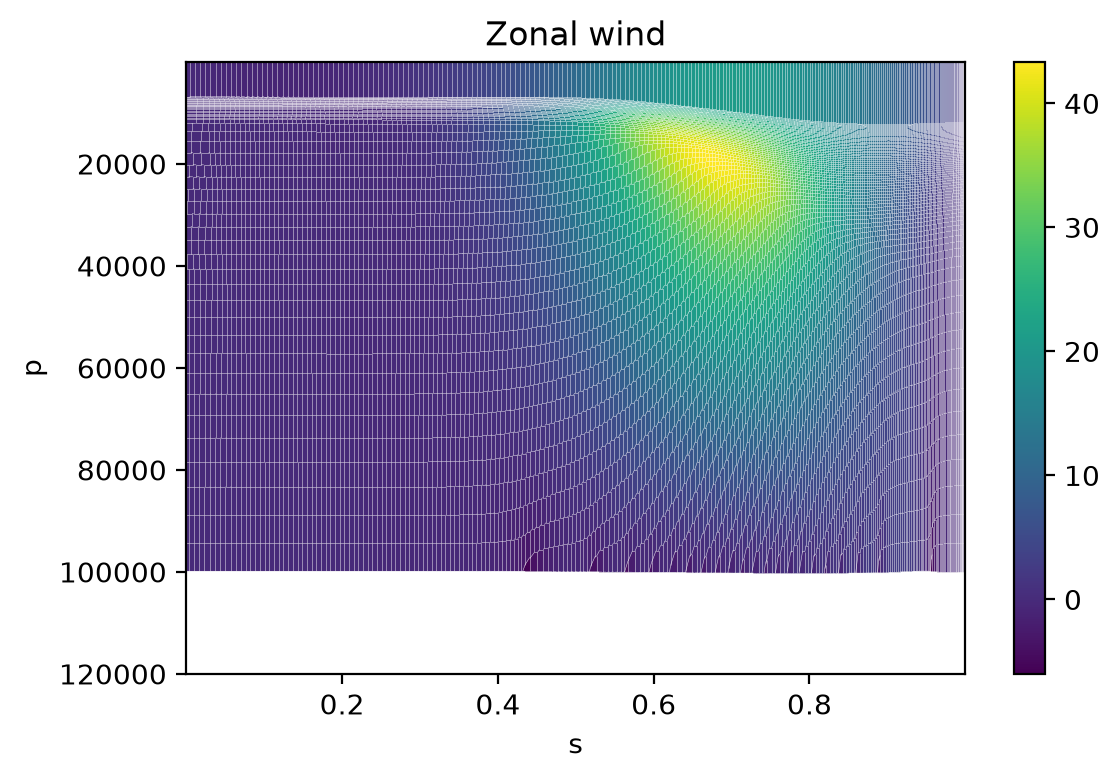

In [12]:
ld = solv.ld
ld.sim.pmax = 1.2*1e+5
z = solv.y[:,0]
th = solv.y[:,1]
u = atmosphere_bgs.get_u(ld)

rz, axz = atmosphere_bgs.plot_lag_tess(ld,val=z,line_clr='white')
axz.set_title('Zonal angular momentum')

rth, axth = atmosphere_bgs.plot_lag_tess(ld,val=th,line_clr='white')
axth.set_title('Potential temperature')

rth, axu = atmosphere_bgs.plot_lag_tess(ld,val=u,line_clr='white')
axu.set_title('Zonal wind')

for ax in [axz,axth,axu]:
    ax.invert_yaxis()
    ax.set_xlabel('s')
    ax.set_ylabel('p')

The surface pressure of the MLM state is obtained as part of the optimal transport solution. A large portion of the domain $X$ found to be below ground in the MLM state and the boundary of this portion of the domain is the surface pressure.

We plot the surface pressure that is obtained directly from the smei-discrete optimal transport solver.

(99000.0, 101000.0)

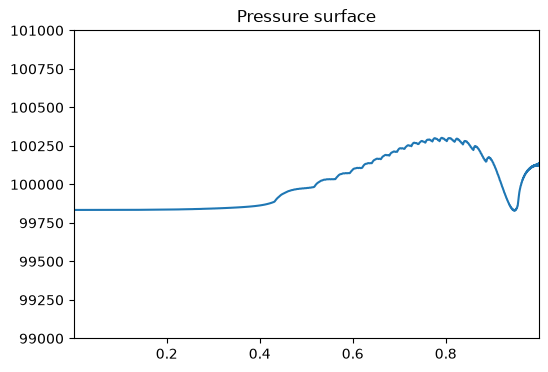

In [10]:
ax = atmosphere_bgs.plot_pressure_surface(ld)
ax.set_ylim([.99*1e+5,1.01*1e+5])

We now apply several post-processing steps to obtain a smooth MLM state in pressure coordinates $(s,p)$ and isentropic coordinates $(\phi,\theta)$, where $\phi$ is latitude in degress.

The main steps applied here are kernel smoothing in pressure coordinates and interpolation onto isentropic levels. The output is an xarray dataset that can be saved to netCDF format using the function `atmosphere_bgs.data_io.save_to_netCDF`.

We note that it is only the geopotential that is directly smoothed in pressure coordinates. All other variables in pressure coordinates are derived from the smooth geopotential using gradient wind and hydrostatic balance.

In [ ]:
# post process the MLM state
bscirc = input_data.bscirc
pvlevs = input_data.pvlevs
thlevs = input_data.thlevs
pvmaxth = input_data.data_dict['pvmaxth']
    
mlm = atmosphere_bgs.PostProcessor(solv,bscirc,pvlevs,thlevs,pvmaxth,eps=1e-3,res=[180,180],make_surface_adjustments=True)

# put the post-processed data into a dictionary
data_dict = atmosphere_bgs.data_io.get_mlm_data_dict(mlm)

# convert the dictionary to an xarray dataset and (optionally) save to netCDF
ds = atmosphere_bgs.data_io.save_bgs_to_netCDF(data_dict,file_path=None) # to save on a path specify file_path

fixed 253 intersects
No file path specified. Dataset generated in memory only.


The data variables of the `xarray` dataset can be plotted using the inbuilt functions, or they can be detached as numpy arrays.

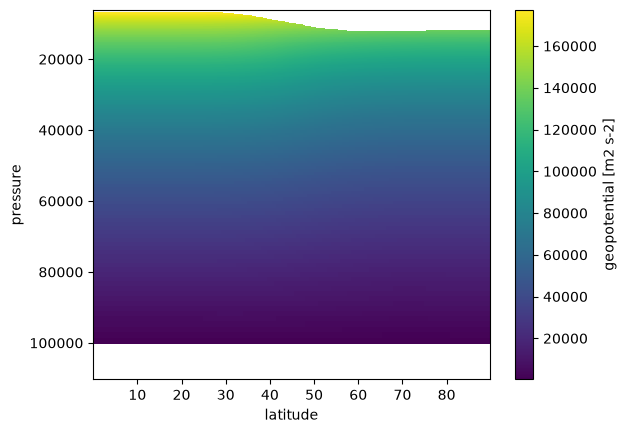

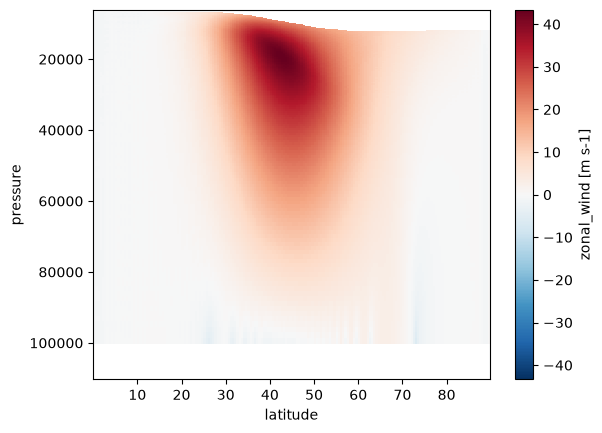

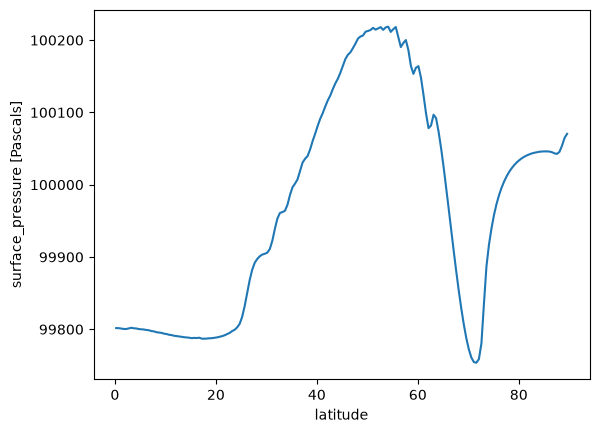

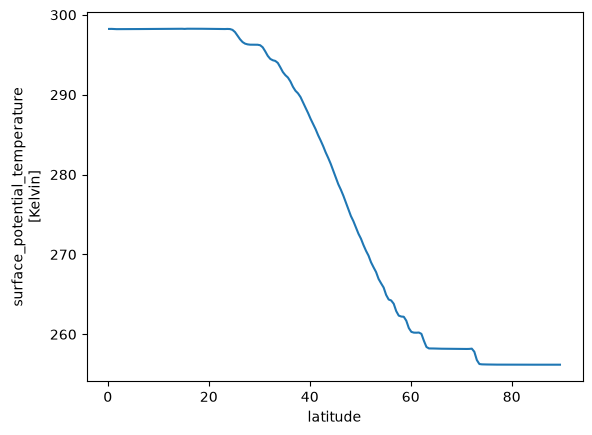

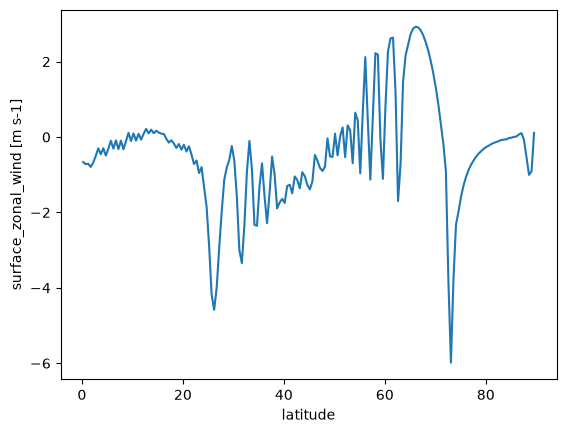

In [ ]:
geopotential_np  = ds.geopotential.values                       # numpy array of gridded smoothed geopotential

plt.figure()
gp_plot = ds.geopotential.plot(y='pressure',yincrease=False)    # plot of smoothed geopotential using inbuilt xarray plotting

plt.figure()
u_plot = ds.zonal_wind.plot(y='pressure',yincrease=False)       # plot of smoothed zonal wind using inbuilt xarray plotting

plt.figure()
ds.surface_pressure.plot()              # plot of smoothed surface pressure

plt.figure()
ds.surface_potential_temperature.plot() # plot of smoothed surface potential temperature

plt.figure()
ds.surface_zonal_wind.plot()            # plot of smooth surface zonal wind